In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [23]:
df=pd.read_csv(r"D:\ML\PYTHON\LR car dataset\CarDetails.csv")


In [24]:
import pandas as pd
df = pd.read_csv(r"D:\ML\PYTHON\LR car dataset\CarDetails.csv")
print(df.shape)
print(df.head())
print(df.dtypes)
print(df.isnull().sum())

(815, 4)
   Year   Price  Kms_driven    Fuel
0  2007   80000       45000  Petrol
1  2006  425000          40  Diesel
2  2014  325000       28000  Petrol
3  2014  575000       36000  Diesel
4  2012  175000       41000  Diesel
Year           int64
Price          int64
Kms_driven     int64
Fuel          object
dtype: object
Year          0
Price         0
Kms_driven    0
Fuel          0
dtype: int64


In [25]:
df_encoded = pd.get_dummies(df, columns=['Fuel'], drop_first=True)
print(df_encoded.head())

   Year   Price  Kms_driven  Fuel_LPG  Fuel_Petrol
0  2007   80000       45000     False         True
1  2006  425000          40     False        False
2  2014  325000       28000     False         True
3  2014  575000       36000     False        False
4  2012  175000       41000     False        False


In [26]:
df_encoded = pd.get_dummies(df, columns=['Fuel'], drop_first=True)
print(df_encoded.head())
print(df_encoded.dtypes)


   Year   Price  Kms_driven  Fuel_LPG  Fuel_Petrol
0  2007   80000       45000     False         True
1  2006  425000          40     False        False
2  2014  325000       28000     False         True
3  2014  575000       36000     False        False
4  2012  175000       41000     False        False
Year           int64
Price          int64
Kms_driven     int64
Fuel_LPG        bool
Fuel_Petrol     bool
dtype: object


In [27]:
y = df_encoded['Price']
X = df_encoded.drop('Price', axis=1)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(652, 4) (163, 4) (652,) (163,)


In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(652, 4) (163, 4) (652,) (163,)


In [29]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [30]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(652, 4) (163, 4) (652,) (163,)


In [31]:
print(model.coef_)
print(model.intercept_)

[ 2.49333577e+04 -1.23939140e+00 -1.94880726e+05 -1.68128202e+05]
-49635971.612218685


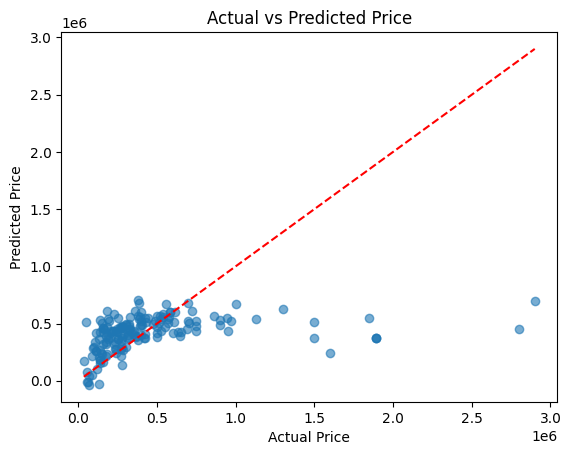

In [32]:


import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # perfect prediction line
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")
plt.show()

In [33]:
import pandas as pd

new_car = pd.DataFrame({
    'Year': [2013],
    'Kms_driven': [25000],
    'Fuel_LPG': [0],
    'Fuel_Petrol': [1]
})

predicted_price = model.predict(new_car)
print(predicted_price)

[355764.42906954]


In [34]:
row_number = 2  # change this to any row index you want, 0 to 162

print("Features:")
print(X_test.iloc[row_number])

print("\nActual Price:", y_test.iloc[row_number])
print("Predicted Price:", model.predict(X_test.iloc[[row_number]])[0])

Features:
Year            2011
Kms_driven     65000
Fuel_LPG       False
Fuel_Petrol    False
Name: 388, dtype: object

Actual Price: 245000
Predicted Price: 424450.2595734447


In [15]:
avg_price = y_test.mean()
mae_percent = (mae / avg_price) * 100
print(f"Average Price: {avg_price}")
print(f"MAE as % of average price: {mae_percent:.2f}%")

NameError: name 'mae' is not defined

In [35]:
avg_price = y_test.mean()
mae_percent = (mae / avg_price) * 100
print(f"Average Price: {avg_price}")
print(f"MAE as % of average price: {mae_percent:.2f}%")

Average Price: 449774.52147239266
MAE as % of average price: 51.72%


In [36]:
train_pred = model.predict(X_train)
train_r2 = r2_score(y_train, train_pred)
print("Train R2:", train_r2)
print("Test R2:", r2)

Train R2: 0.1692353026105885
Test R2: 0.11781545439029639


In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print('MAE:', mae)
print('RMSE:', rmse)
print('R2:', r2)


MAE: 232640.96234327156
RMSE: 423850.1358449093
R2: 0.11781545439029639


In [40]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Load dataset
df = pd.read_csv(r"D:\ML\PYTHON\LR car dataset\CarDetails.csv")

# Input and output
X = df[['Year']]
y = df['Price']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Polynomial features
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Model
model = LinearRegression()

model.fit(X_train_poly, y_train)

# Prediction
y_pred = model.predict(X_test_poly)

# Evaluation
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))

MAE: 237617.35785744013
R²: 0.11142363459250293


   Year   Price  Kms_driven    Fuel
0  2007   80000       45000  Petrol
1  2006  425000          40  Diesel
2  2014  325000       28000  Petrol
3  2014  575000       36000  Diesel
4  2012  175000       41000  Diesel
Index(['Year', 'Price', 'Kms_driven', 'Fuel'], dtype='object')

Model Evaluation
----------------
MAE  : 237617.35785744013
MSE  : 180950574192.08856
RMSE : 425382.8560157174
R²   : 0.11142363459250293


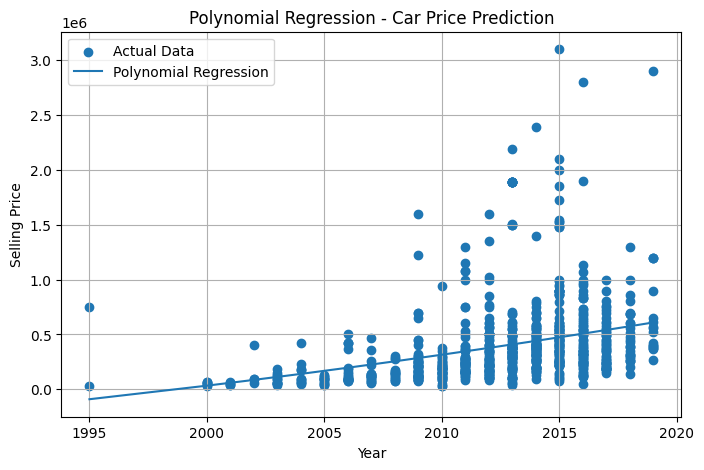

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------------------------
# 1. Load dataset
# --------------------------------------------------

df = pd.read_csv(r"D:\ML\PYTHON\LR car dataset\CarDetails.csv")

# Check data
print(df.head())
print(df.columns)


# --------------------------------------------------
# 2. Select X and y
# --------------------------------------------------

X = df[['Year']]
y = df['Price']


# --------------------------------------------------
# 3. Train-Test Split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# --------------------------------------------------
# 4. Create Polynomial Features
# --------------------------------------------------

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)


# --------------------------------------------------
# 5. Create and Train Model
# --------------------------------------------------

model = LinearRegression()

model.fit(X_train_poly, y_train)


# --------------------------------------------------
# 6. Prediction
# --------------------------------------------------

y_pred = model.predict(X_test_poly)


# --------------------------------------------------
# 7. Evaluation
# --------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation")
print("----------------")
print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R²   :", r2)


# --------------------------------------------------
# 8. Visualization
# --------------------------------------------------

# Sort X values so that the curve is smooth
X_plot = X.sort_values(by='Year')

X_plot_poly = poly.transform(X_plot)

y_plot = model.predict(X_plot_poly)

plt.figure(figsize=(8, 5))

plt.scatter(X, y, label="Actual Data")

plt.plot(
    X_plot,
    y_plot,
    label="Polynomial Regression"
)

plt.xlabel("Year")
plt.ylabel("Selling Price")
plt.title("Polynomial Regression - Car Price Prediction")

plt.legend()
plt.grid(True)

plt.show()